# Momentum Factor Research

## Research question

**Does medium-term price momentum predict next-month cross-sectional stock returns in a portfolio of large Indian equities?**

This project tests the relationship between historical momentum and subsequent one-month returns using:

- **Momentum formation horizons:** 3, 6, 9 and 12 months
- **Forward return horizon:** 1 month
- **Signal evaluation:** Spearman Rank IC
- **Portfolio test:** Quintile-sorted portfolios
- **Long-short test:** Q5 − Q1 return spread
- **Statistical test:** One-sample t-test against zero
- **Data:** Adjusted monthly prices downloaded from Yahoo Finance

The objective is to follow a systematic research loop:

> **Hypothesis → Data → Signal → Cross-sectional test → Portfolio test → Statistical test → Interpretation**

> **Important:** This is an educational research project, not investment advice. Results depend on the universe, sample period, data source and methodology.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import t

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

## 2. Data loader and validation

The loader downloads adjusted closing prices, sorts observations chronologically and checks for:

- missing prices
- non-positive prices
- duplicate dates
- a valid `DatetimeIndex`

Only validation errors are printed, making the data-cleaning step easier to audit.

In [2]:
class DataLoader:
    def __init__(self, tickers, start, end):
        self.tickers = tickers
        self.start = start
        self.end = end

    def download(self):
        prices = yf.download(
            self.tickers,
            start=self.start,
            end=self.end,
            auto_adjust=True,
            progress=False
        )["Close"]

        return prices

    @staticmethod
    def clean_data(df):
        df = df.copy()
        df.index = pd.to_datetime(df.index)
        return df.sort_index()

    @staticmethod
    def validate_data(df):
        errors = []

        missing = df.isna().any(axis=1)
        if missing.any():
            errors.append("Missing values detected in these rows:")
            errors.append(str(df.loc[missing]))

        invalid_prices = (df <= 0).any(axis=1)
        if invalid_prices.any():
            errors.append("Non-positive prices detected in these rows:")
            errors.append(str(df.loc[invalid_prices]))

        duplicated_dates = df.index.duplicated(keep=False)
        if duplicated_dates.any():
            errors.append("Duplicate dates detected:")
            errors.append(str(df.loc[duplicated_dates]))

        if not isinstance(df.index, pd.DatetimeIndex):
            errors.append("Index is not a DatetimeIndex.")

        if errors:
            print("\n".join(errors))
        else:
            print("Validation passed: no structural errors detected.")

    @staticmethod
    def observations(df):
        return df.notna().sum().sort_values()

## 3. Equity universe

The universe contains 49 large Indian listed companies across financials, technology, consumer, industrials, healthcare, energy and other sectors.

The sample runs from **March 2021 through August 2026**.

In [3]:
tickers = [
    "HDFCBANK.NS", "ICICIBANK.NS", "RELIANCE.NS", "BHARTIARTL.NS",
    "LT.NS", "SBIN.NS", "INFY.NS", "AXISBANK.NS", "KOTAKBANK.NS",
    "M&M.NS", "ITC.NS", "TCS.NS", "BAJFINANCE.NS", "HINDUNILVR.NS",
    "MARUTI.NS", "SUNPHARMA.NS", "NTPC.NS", "TITAN.NS", "TATASTEEL.NS",
    "BEL.NS", "SHRIRAMFIN.NS", "ULTRACEMCO.NS", "HCLTECH.NS",
    "POWERGRID.NS", "HINDALCO.NS", "JSWSTEEL.NS", "BAJAJFINSV.NS",
    "ADANIPORTS.NS", "BAJAJ-AUTO.NS", "EICHERMOT.NS", "INDIGO.NS",
    "ONGC.NS", "ASIANPAINT.NS", "GRASIM.NS", "COALINDIA.NS",
    "NESTLEIND.NS", "SBILIFE.NS", "TRENT.NS", "TECHM.NS",
    "MAXHEALTH.NS", "APOLLOHOSP.NS", "TMPV.NS", "DRREDDY.NS",
    "HDFCLIFE.NS", "CIPLA.NS", "TATACONSUM.NS", "WIPRO.NS",
    "ADANIENT.NS"
]

loader = DataLoader(
    tickers=tickers,
    start="2021-03-01",
    end="2026-09-01"
)

prices_daily = loader.download()
prices_daily = loader.clean_data(prices_daily)

# Keep the research sample through August 2026.
prices_daily = prices_daily.loc[prices_daily.index <= "2026-08-31"]

loader.validate_data(prices_daily)
loader.observations(prices_daily).head()

Missing values detected in these rows:
Ticker      ADANIENT.NS  ADANIPORTS.NS  APOLLOHOSP.NS  ASIANPAINT.NS  \
Date                                                                   
2026-05-01    2407.3235      1650.3447      7627.6206      2423.4739   

Ticker      AXISBANK.NS  BAJAJ-AUTO.NS  BAJAJFINSV.NS  BAJFINANCE.NS   BEL.NS  \
Date                                                                            
2026-05-01    1267.3226      9855.3037      1745.7103       931.2753 430.7153   

Ticker      BHARTIARTL.NS  ...  SUNPHARMA.NS  TATACONSUM.NS  TATASTEEL.NS  \
Date                       ...                                              
2026-05-01      1863.3494  ...     1803.5732      1134.9960      207.0892   

Ticker        TCS.NS  TECHM.NS  TITAN.NS  TMPV.NS  TRENT.NS  ULTRACEMCO.NS  \
Date                                                                         
2026-05-01 2427.4951 1436.1779 4370.8579 338.7401 2758.9897     11354.2412   

Ticker      WIPRO.NS  
Date      

Ticker
INDIGO.NS        1362
ADANIENT.NS      1363
APOLLOHOSP.NS    1363
ADANIPORTS.NS    1363
AXISBANK.NS      1363
dtype: int64

## 4. Convert daily prices to month-end prices

Momentum is evaluated using month-end observations. This avoids mixing daily and monthly frequencies and makes the formation/holding-period definitions explicit.

In [4]:
prices_monthly = prices_daily.resample("ME").last()

print(f"Monthly observations: {prices_monthly.shape[0]}")
print(f"Stocks: {prices_monthly.shape[1]}")

Monthly observations: 66
Stocks: 48


## 5. Research engine

For each formation horizon:

1. Calculate cumulative past return over the formation period.
2. Calculate next-month return.
3. At each month, compute the cross-sectional Spearman correlation between momentum and future return (**Rank IC**).
4. Sort stocks into five momentum quintiles.
5. Measure the average return of each quintile.
6. Calculate the Q5 − Q1 long-short spread.
7. Calculate yearly average Rank IC.
8. Estimate the cross-sectional regression slope (beta) between momentum and forward return.

In [5]:
class MomentumResearch:
    def __init__(self, prices, formation_months):
        self.prices = prices
        self.formation_months = formation_months

        self.momentum = None
        self.future_return = None
        self.common_dates = None
        self.rank_ic = None
        self.quintile_returns = None
        self.spread = None
        self.yearly_ic = None
        self.beta = None

    def calculate_momentum(self):
        self.momentum = self.prices.pct_change(
            periods=self.formation_months
        )

    def calculate_forward_return(self):
        self.future_return = self.prices.pct_change().shift(-1)

    def align_data(self):
        self.common_dates = self.momentum.index.intersection(
            self.future_return.index
        )

    def calculate_rank_ic(self):
        rank_ic = {}

        for date in self.common_dates:
            data = pd.concat(
                [
                    self.momentum.loc[date].rename("Momentum"),
                    self.future_return.loc[date].rename("Future_Return")
                ],
                axis=1
            ).dropna()

            if len(data) >= 5:
                rank_ic[date] = data["Momentum"].corr(
                    data["Future_Return"],
                    method="spearman"
                )

        self.rank_ic = pd.Series(rank_ic, dtype=float).dropna()

    def quintile_analysis(self):
        quintile_returns = []
        valid_dates = []

        for date in self.common_dates:
            data = pd.concat(
                [
                    self.momentum.loc[date],
                    self.future_return.loc[date]
                ],
                axis=1
            )
            data.columns = ["momentum", "future_return"]
            data = data.dropna()

            if len(data) < 5:
                continue

            try:
                quintiles = pd.qcut(
                    data["momentum"],
                    q=5,
                    labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
                    duplicates="drop"
                )
            except ValueError:
                continue

            if quintiles.nunique() < 5:
                continue

            returns = data["future_return"].groupby(
                quintiles,
                observed=True
            ).mean()

            if len(returns) == 5:
                quintile_returns.append(returns)
                valid_dates.append(date)

        self.quintile_returns = pd.DataFrame(
            quintile_returns,
            index=valid_dates
        )

    def calculate_spread(self):
        self.spread = (
            self.quintile_returns["Q5"]
            - self.quintile_returns["Q1"]
        )

    def calculate_yearly_ic(self):
        self.yearly_ic = (
            self.rank_ic.groupby(self.rank_ic.index.year).mean()
        )

    def calculate_beta(self):
        betas = {}

        for date in self.common_dates:
            data = pd.concat(
                [
                    self.momentum.loc[date].rename("Momentum"),
                    self.future_return.loc[date].rename("Future_Return")
                ],
                axis=1
            ).dropna()

            if len(data) < 5 or data["Momentum"].var() == 0:
                continue

            x = data["Momentum"].to_numpy()
            y = data["Future_Return"].to_numpy()

            betas[date] = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)

        self.beta = pd.Series(betas, dtype=float).dropna()

    def run(self):
        self.calculate_momentum()
        self.calculate_forward_return()
        self.align_data()
        self.calculate_rank_ic()
        self.quintile_analysis()
        self.calculate_spread()
        self.calculate_yearly_ic()
        self.calculate_beta()
        return self

## 6. Statistical testing

The null hypothesis for both Rank IC and the Q5 − Q1 spread is:

> **H₀: Mean signal/portfolio spread = 0**

A two-sided one-sample t-test is used at the 5% significance level.

In [6]:
def hypothesis_test(series, alpha=0.05):
    series = pd.Series(series).dropna()

    mean = series.mean()
    sd = series.std()
    n = series.count()

    se = sd / np.sqrt(n)
    t_stat = mean / se

    degrees_of_freedom = n - 1
    t_critical = t.ppf(
        1 - alpha / 2,
        degrees_of_freedom
    )

    return {
        "mean": mean,
        "t_stat": t_stat,
        "t_critical": t_critical,
        "n": n,
        "significant": abs(t_stat) > t_critical
    }

## 7. Run 3M / 6M / 9M / 12M momentum tests

In [7]:
researches = {
    "3M": MomentumResearch(prices_monthly, 3).run(),
    "6M": MomentumResearch(prices_monthly, 6).run(),
    "9M": MomentumResearch(prices_monthly, 9).run(),
    "12M": MomentumResearch(prices_monthly, 12).run()
}

## 8. Cross-sectional Rank IC results

In [8]:
results = []

for horizon, research in researches.items():
    ic = hypothesis_test(research.rank_ic)

    results.append({
        "Horizon": horizon,
        "Mean Rank IC": ic["mean"],
        "IC t-stat": ic["t_stat"],
        "IC Significant": ic["significant"],
        "Observations": ic["n"]
    })

ic_comparison = pd.DataFrame(results)
ic_comparison

,Horizon,Mean Rank IC,IC t-stat,IC Significant,Observations
0,3M,-0.0685,-2.5114,True,62
1,6M,-0.0365,-1.2111,False,59
2,9M,-0.0117,-0.3774,False,56
3,12M,0.0118,0.3908,False,53


### Rank IC interpretation

A positive Rank IC means stocks with higher momentum tended to have higher next-month returns in that month. The average Rank IC summarizes whether this relationship persisted across the sample.

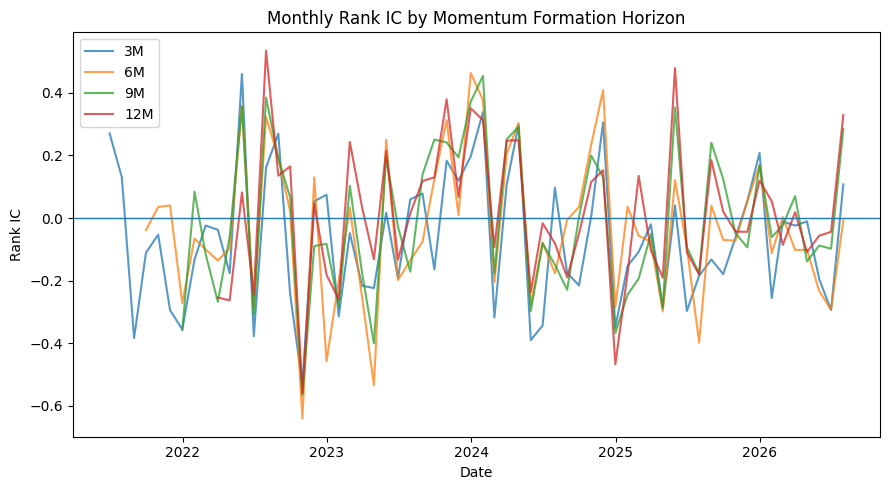

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

for horizon, research in researches.items():
    ax.plot(
        research.rank_ic.index,
        research.rank_ic.values,
        label=horizon,
        alpha=0.75
    )

ax.axhline(0, linewidth=1)
ax.set_title("Monthly Rank IC by Momentum Formation Horizon")
ax.set_xlabel("Date")
ax.set_ylabel("Rank IC")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Quintile portfolio test

At each month, stocks are sorted from lowest to highest momentum:

- **Q1:** lowest momentum
- **Q5:** highest momentum

The long-short portfolio is:

**Q5 − Q1**

This provides a portfolio-level test in addition to the stock-level Rank IC test.

In [10]:
quintile_summary = []

for horizon, research in researches.items():
    mean_returns = research.quintile_returns.mean()
    spread_test = hypothesis_test(research.spread)

    row = {"Horizon": horizon}
    row.update(mean_returns.to_dict())
    row["Q5-Q1 Spread"] = spread_test["mean"]
    row["Spread t-stat"] = spread_test["t_stat"]
    row["Spread Significant"] = spread_test["significant"]
    quintile_summary.append(row)

quintile_comparison = pd.DataFrame(quintile_summary)
quintile_comparison

,Horizon,Q1,Q2,Q3,Q4,Q5,Q5-Q1 Spread,Spread t-stat,Spread Significant
0,3M,0.0203,0.0196,0.0140,0.0087,0.0094,-0.0109,-1.9744,False
1,6M,0.0134,0.0199,0.0129,0.0071,0.0107,-0.0027,-0.4325,False
2,9M,0.0157,0.0131,0.0109,0.0128,0.0135,-0.0022,-0.3576,False
3,12M,0.0150,0.0131,0.0126,0.0132,0.0141,-0.0009,-0.1476,False


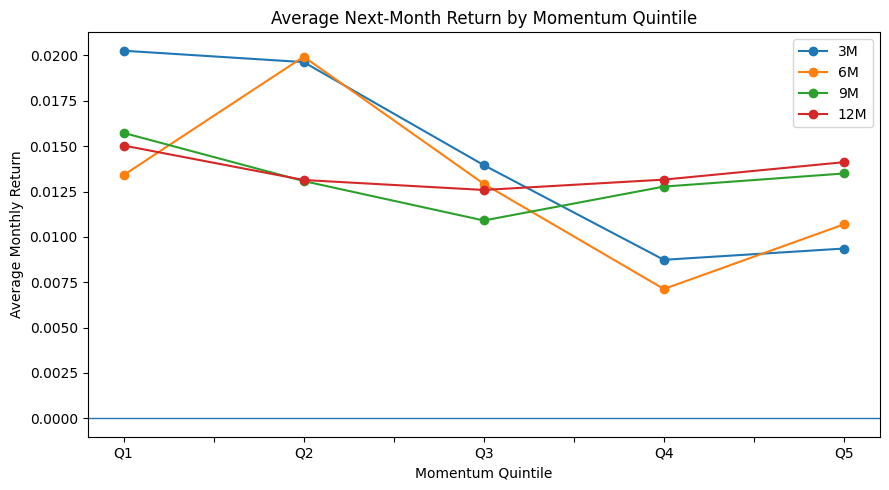

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))

for horizon, research in researches.items():
    research.quintile_returns.mean().plot(
        kind="line",
        marker="o",
        ax=ax,
        label=horizon
    )

ax.axhline(0, linewidth=1)
ax.set_title("Average Next-Month Return by Momentum Quintile")
ax.set_xlabel("Momentum Quintile")
ax.set_ylabel("Average Monthly Return")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Year-by-year stability

A factor can look strong in aggregate but be concentrated in a small part of the sample. Yearly Rank IC helps check whether the relationship is reasonably persistent.

In [12]:
yearly_ic = pd.DataFrame({
    horizon: research.yearly_ic
    for horizon, research in researches.items()
})

yearly_ic

,3M,6M,9M,12M
2021,-0.1138,-0.0588,-0.3577,NaN
2022,-0.0420,-0.0632,-0.0339,-0.0540
2023,-0.0420,-0.0169,0.0363,0.0856
2024,-0.0532,0.0445,0.0025,-0.0048
2025,-0.0935,-0.0537,-0.0251,0.0075
2026,-0.0975,-0.1210,-0.0078,0.0152


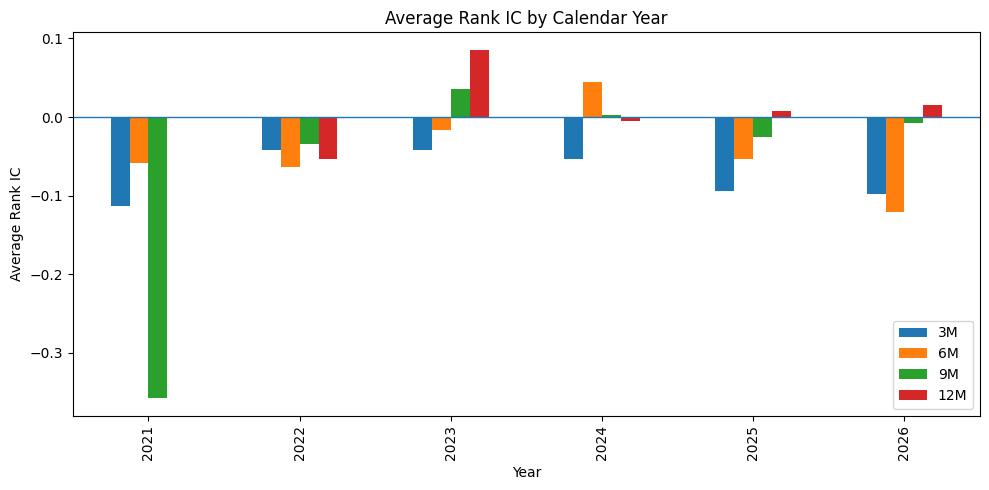

In [13]:
yearly_ic.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.axhline(0, linewidth=1)
plt.title("Average Rank IC by Calendar Year")
plt.xlabel("Year")
plt.ylabel("Average Rank IC")
plt.tight_layout()
plt.show()

## 11. Negative-IC frequency

The percentage of months with a negative Rank IC gives another view of consistency. A factor can have a positive average IC while still failing in a substantial fraction of months.

In [14]:
consistency = pd.DataFrame({
    "Negative IC %": {
        horizon: (research.rank_ic < 0).mean()
        for horizon, research in researches.items()
    }
})

consistency

,Negative IC %
3M,0.6290
6M,0.5763
9M,0.5714
12M,0.4906


## 12. Regression beta

The cross-sectional beta estimates the slope of the relationship:

**Forward Return = α + β × Momentum + ε**

A positive beta indicates that higher momentum was associated with higher subsequent returns on average.

In [15]:
beta_summary = pd.DataFrame({
    "Mean Beta": {
        horizon: research.beta.mean()
        for horizon, research in researches.items()
    }
})

beta_summary

,Mean Beta
3M,-0.0332
6M,-0.0198
9M,-0.0077
12M,0.0010


## 13. Final research dashboard

In [22]:
final_results = []

for horizon, research in researches.items():
    ic = hypothesis_test(research.rank_ic)
    spread = hypothesis_test(research.spread)
    Beta = hypothesis_test(research.beta)

    final_results.append({
        "Horizon": horizon,
        "Mean Rank IC": ic["mean"],
        "IC t-stat": ic["t_stat"],
        "IC Significant": ic["significant"],
        "Mean Q5-Q1": spread["mean"],
        "Spread t-stat": spread["t_stat"],
        "Spread Significant": spread["significant"],
        "Negative IC %": (research.rank_ic < 0).mean(),
        "Mean Beta": research.beta.mean(),
        "Beta t-stat": Beta["t_stat"],
        "Beta Significant": Beta["significant"]
    })

final_dashboard = pd.DataFrame(final_results).set_index("Horizon")
final_dashboard.round(4)

,Mean Rank IC,IC t-stat,IC Significant,Mean Q5-Q1,Spread t-stat,Spread Significant,Negative IC %,Mean Beta,Beta t-stat,Beta Significant
Horizon,,,,,,,,,,
3M,-0.0685,-2.5114,True,-0.0109,-1.9744,False,0.6290,-0.0332,-1.9584,False
6M,-0.0365,-1.2111,False,-0.0027,-0.4325,False,0.5763,-0.0198,-1.3832,False
9M,-0.0117,-0.3774,False,-0.0022,-0.3576,False,0.5714,-0.0077,-0.6903,False
12M,0.0118,0.3908,False,-0.0009,-0.1476,False,0.4906,0.0010,0.1165,False


## 14. Research conclusion

Use the tables above to determine whether the original hypothesis is supported.

A strong conclusion should consider **all three layers of evidence**:

1. **Rank IC:** Is the cross-sectional relationship positive and statistically distinguishable from zero?
2. **Quintile spread:** Does the highest-momentum group outperform the lowest-momentum group?
3. **Stability:** Is the result reasonably persistent across time rather than driven by a small number of observations?

### Important limitations

- The universe is a fixed set of large Indian equities and is **not survivorship-bias free**.
- Yahoo Finance is a convenient public data source but is not a point-in-time institutional database.
- Transaction costs, market impact, turnover and taxes are not included.
- The quintile portfolios are equal-weighted.
- Statistical significance does not establish economic significance or future profitability.
- The sample period is relatively short for factor research.

### Next research steps

A stronger research pipeline could add:

- transaction costs and turnover
- sector-neutral ranking
- market-cap weighting
- volatility adjustment
- value and quality factors
- factor combination
- out-of-sample testing
- rolling-window analysis
- benchmark-relative returns
- portfolio drawdown and risk metrics